In [53]:
import  pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [54]:
# Load the data
df = pd.read_csv('../csv/game_events.csv')

print(df.dtypes)
df

game_event_id        object
date                 object
game_id               int64
minute                int64
type                 object
club_id               int64
player_id             int64
description          object
player_in_id        float64
player_assist_id    float64
dtype: object


,game_event_id,date,game_id,minute,type,club_id,player_id,description,player_in_id,player_assist_id
0,2f41da30c471492e7d4a984951671677,2012-08-05,2211607,77,Cards,610,4425,"1. Yellow card , Mass confrontation",NaN,NaN
1,a72f7186d132775f234d3e2f7bc0ed5b,2012-08-05,2211607,77,Cards,383,33210,"1. Yellow card , Mass confrontation",NaN,NaN
2,b2d721eaed4692a5c59a92323689ef18,2012-08-05,2211607,3,Goals,383,36500,", Header, 1. Tournament Goal Assist: , Corner,...",NaN,56416.0
3,aef768899cedac0c9a650980219075a2,2012-08-05,2211607,53,Goals,383,36500,", Right-footed shot, 2. Tournament Goal Assist...",NaN,146258.0
4,5d6d9533023057b6619ecd145a038bbe,2012-08-05,2211607,74,Substitutions,383,36500,", Not reported",49499.0,NaN
...,...,...,...,...,...,...,...,...,...,...
666553,7f5a6b61ca858e0cd63a58c554b56bb7,2023-11-15,4228114,82,Substitutions,358,874064,", Tactical",965607.0,NaN
666554,5b93d1bc9e8bf42965682d491e1dd6c7,2023-11-15,4228114,44,Goals,46889,922572,", Penalty, 1. Tournament Goal",NaN,NaN
666555,d638b1e72f531c413487d413258a3130,2023-11-15,4228114,68,Substitutions,46889,922572,", Tactical",1200869.0,NaN
666556,0ff7774aa1383af83e40c435325463af,2023-11-15,4228114,68,Substitutions,46889,1200864,", Tactical",921121.0,NaN


### Data Exploration
The dataset contains 10 columns and 666558 rows. The columns are:
- `game_event_id`: The unique identifier for each event
- `date`: The date of the game
- `game_id`: The unique identifier for the game
- `minute`: The minute of the game in which the event occurred
- `type` : The type of the event
- `club_id`: The unique identifier for the club
- `player_id`: The unique identifier for the player
- `description` : The description of the event
- `player_in_id`: The unique identifier for the player in
- `player_assists_id`: The unique identifier for the players that assisted the goal

In [55]:
#check for duplicates
duplicates = df.duplicated().sum()
print(f'There are {duplicates} duplicates in the dataset')

#check for missing values
missing_values = df.isnull().mean() * 100
print("Missing values in the dataset:\n", missing_values)

#convert float values into integers and using -1 like a placeholder for missing values, because we hypothetize that can't be a player with id -1
df['player_in_id'] = df['player_in_id'].fillna(-1).astype(int)
df['player_assist_id'] = df['player_assist_id'].fillna(-1).astype(int)

#filling missing values for description
df['description'] = df['description'].fillna('No description')

#convert date to datetime
df['date'] = pd.to_datetime(df['date'])

There are 0 duplicates in the dataset
Missing values in the dataset:
 game_event_id        0.000000
date                 0.000000
game_id              0.000000
minute               0.000000
type                 0.000000
club_id              0.000000
player_id            0.000000
description         50.456974
player_in_id        36.802349
player_assist_id    95.370695
dtype: float64


### Data Cleaning
- The dataset seems to contain no duplicates
- The columns `player_in_id` and `player_assist_id` contain missing values. We will replace the missing values with -1 and convert the columns to integers.
- The column `date` has type 'object' and we have converted it to datetime.

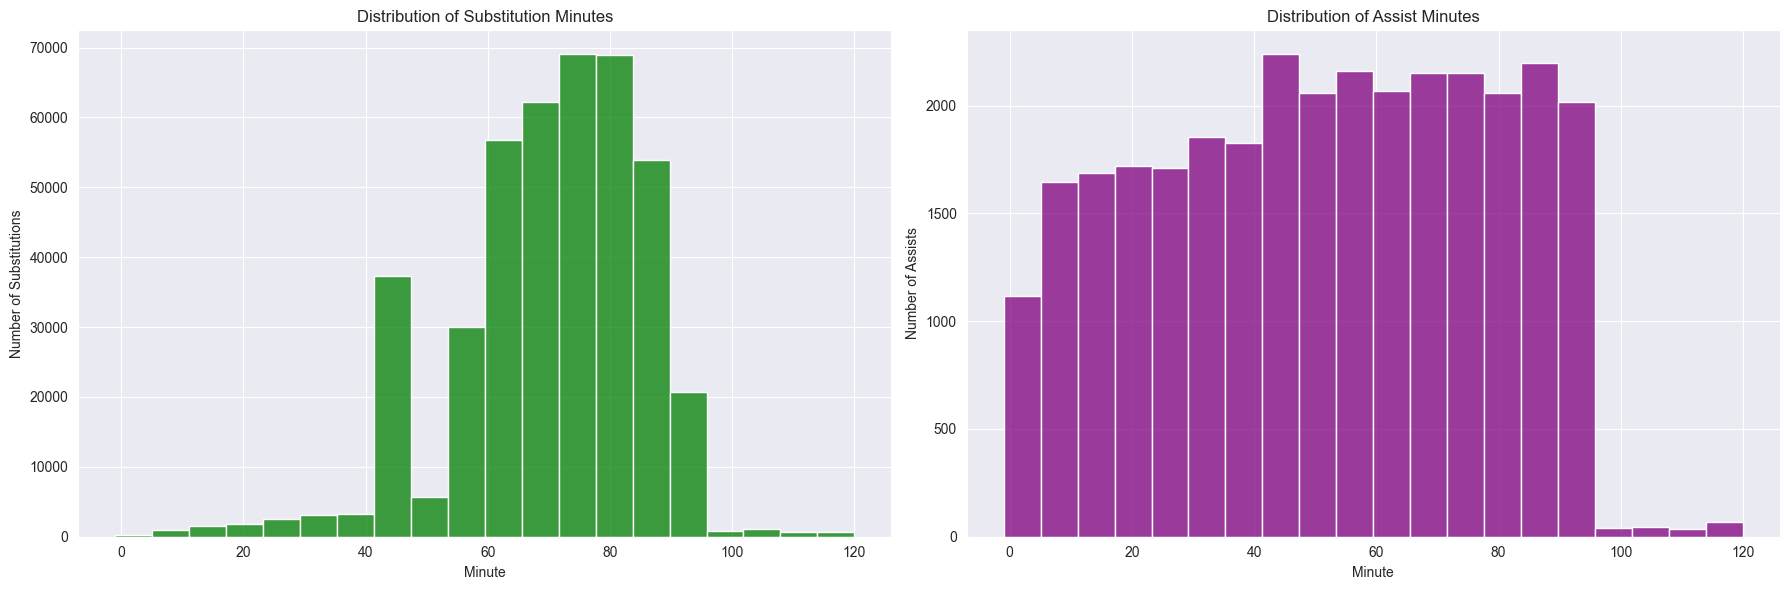

In [56]:
# Create a figure with two subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot for Substitution Minutes on the first subplot
sns.histplot(df[df['player_in_id'] != -1]['minute'], bins=20, kde=False, color='green', ax=axes[0])
axes[0].set_title('Distribution of Substitution Minutes')
axes[0].set_xlabel('Minute')
axes[0].set_ylabel('Number of Substitutions')

# Plot for Assist Minutes on the second subplot
sns.histplot(df[df['player_assist_id'] != -1]['minute'], bins=20, kde=False, color='purple', ax=axes[1])
axes[1].set_title('Distribution of Assist Minutes')
axes[1].set_xlabel('Minute')
axes[1].set_ylabel('Number of Assists')

# Adjust layout for better spacing
plt.tight_layout()

# Show the combined plot
plt.show()


### Distribution of Substitution and Assist Minutes

The two histograms above display the minute-by-minute distribution of two key game events: substitutions and assists.

#### Left Plot: Distribution of Substitution Minutes
This histogram showcases the distribution of minutes during a match when players are substituted. As we can observe:
- Most substitutions occur between the 60th and 80th minute.
- Substitutions increase as the game progresses, peaking around the 80th minute.

#### Right Plot: Distribution of Assist Minutes
This histogram illustrates the distribution of minutes during a match when assists occur. The key points are:
- Assists are more evenly distributed throughout the game.
- There's a relatively consistent number of assists from the start until the 80th minute, with a slight increase around the middle of the match.
- A few assists occur in extra time, but these instances are rare.



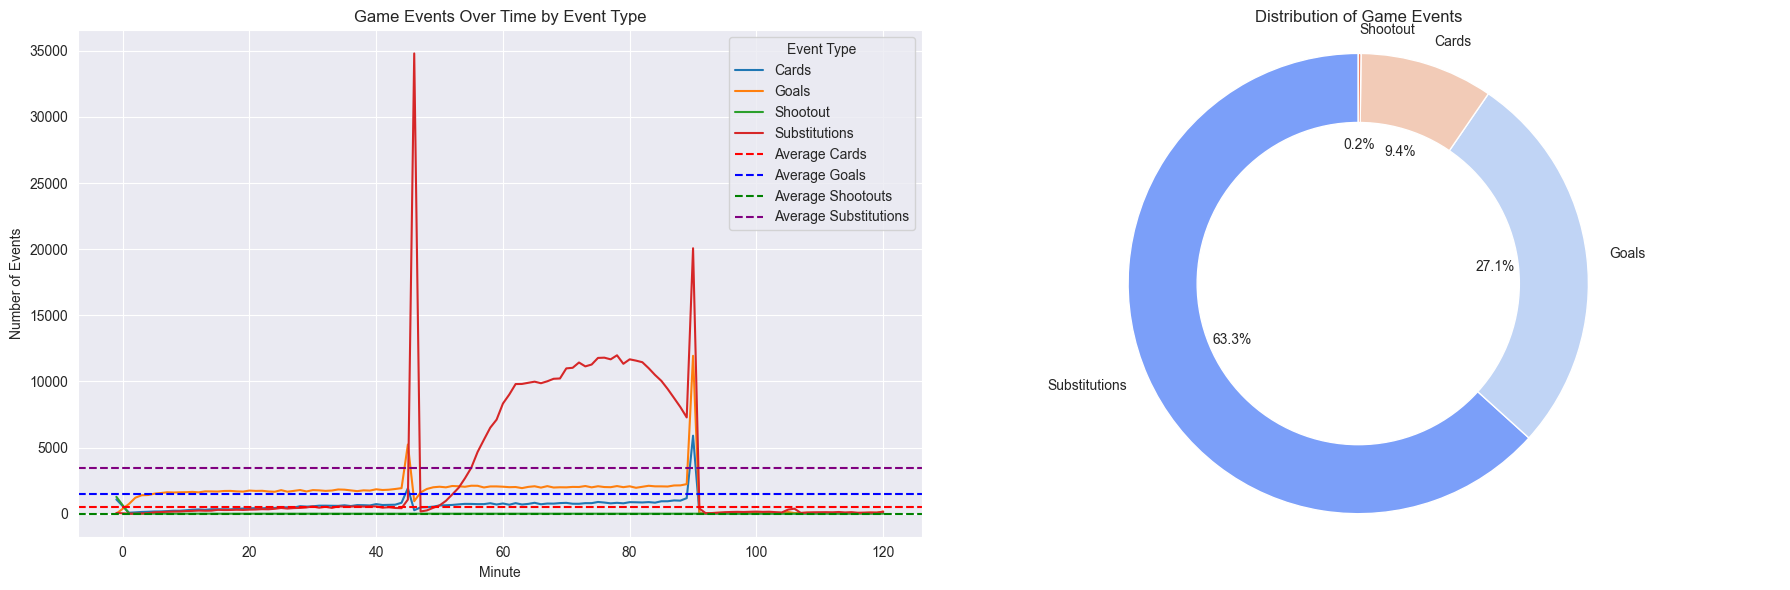

In [57]:
# Set up a figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# First plot: Line plot for event counts over time
event_counts = df.groupby(['minute', 'type']).size().unstack(fill_value=0)
event_counts.plot(kind='line', marker='', ax=axes[0])

# Set titles and labels for the first plot
axes[0].set_title('Game Events Over Time by Event Type')
axes[0].set_xlabel('Minute')
axes[0].set_ylabel('Number of Events')

# Add average lines
axes[0].axhline(y=event_counts['Cards'].mean(), color='red', linestyle='--', label='Average Cards')
axes[0].axhline(y=event_counts['Goals'].mean(), color='blue', linestyle='--', label='Average Goals')
axes[0].axhline(y=event_counts['Shootout'].mean(), color='green', linestyle='--', label='Average Shootouts')
axes[0].axhline(y=event_counts['Substitutions'].mean(), color='purple', linestyle='--', label='Average Substitutions')

# Add a legend to the first plot
axes[0].legend(title='Event Type')
axes[0].grid(True)

# Second plot: Pie chart for event distribution
event_count = df['type'].value_counts()
axes[1].pie(event_count, labels=event_count.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('coolwarm', len(event_count)))

# Add a circle in the center of the pie chart
center_circle = plt.Circle((0, 0), 0.70, fc='white')
axes[1].add_artist(center_circle)

# Set title for the second plot
axes[1].set_title('Distribution of Game Events')

# Ensure the pie chart is drawn as a circle
axes[1].axis('equal')

# Adjust the layout to make it tight
plt.tight_layout()
plt.show()


### Game Events Analysis: Line Plot and Pie Chart

This analysis presents two visualizations side by side to explore game events over time and the distribution of different event types.

#### 1. Game Events Over Time by Event Type (Line Plot)

On the left, the line plot displays the number of different game events (such as **Goals**, **Cards**, **Shootouts**, and **Substitutions**) over the minutes in a game. Each event type is represented by a distinct color.

- The **Y-axis** shows the number of events, while the **X-axis** represents the minute of the game.
- Several dashed horizontal lines represent the average number of each event type, providing a reference to identify moments of significantly higher or lower activity.
- Key observations include spikes in goals and substitutions around the 45th and 90th minutes, which likely correspond to half-time and full-time, where substitutions or critical moments in the game happen.

#### 2. Distribution of Game Events (Pie Chart)

The right visualization is a **donut chart** that shows the overall distribution of game event types in the dataset:
- **Substitutions** dominate the game events, accounting for **63.3%** of all occurrences.
- **Goals** represent **27.1%** of the events.
- **Cards** account for **9.4%**, while **Shootouts** contribute a minimal **0.2%**.

The pie chart highlights the relative frequencies of each event type, making it easier to understand which events occur most frequently in the game data.


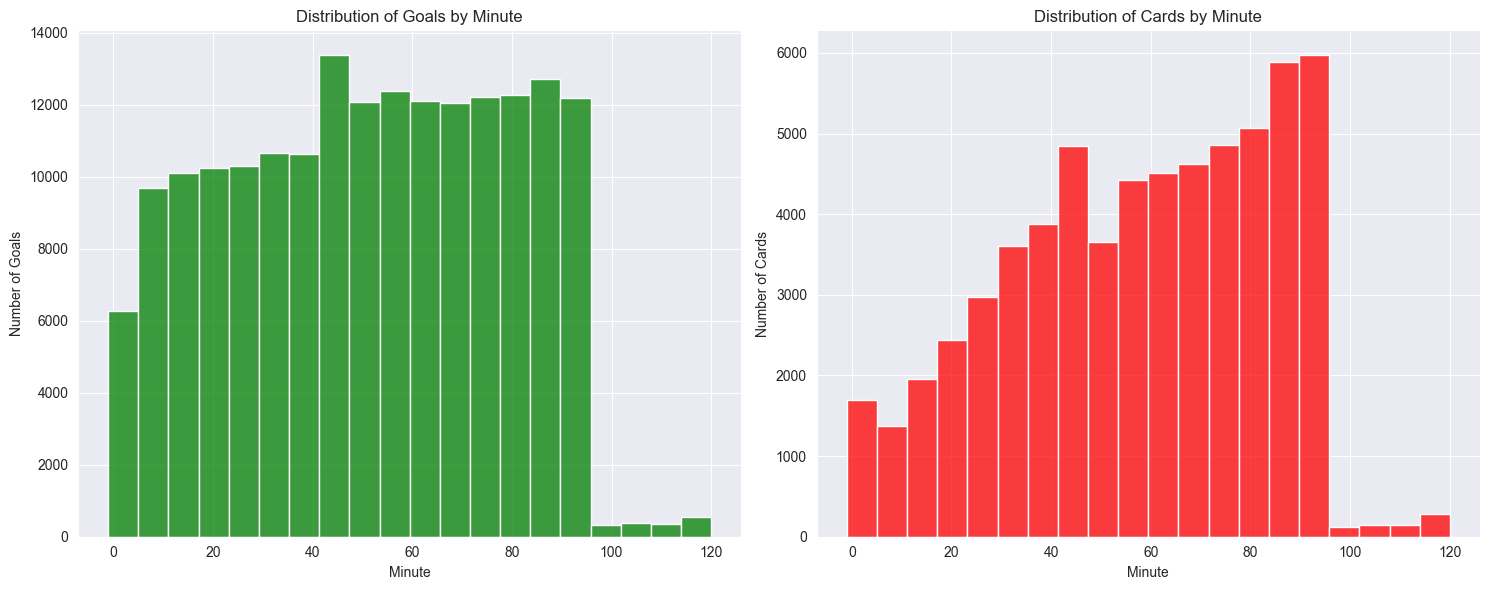

In [58]:
# Create a figure with 1 row and 2 columns
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Plot for Goals
sns.histplot(df[df['type'] == 'Goals']['minute'], bins=20, kde=False, color='green', ax=axs[0])
axs[0].set_title('Distribution of Goals by Minute')
axs[0].set_xlabel('Minute')
axs[0].set_ylabel('Number of Goals')

# Plot for Shootouts
sns.histplot(df[df['type'] == 'Cards']['minute'], bins=20, kde=False, color='red', ax=axs[1])
axs[1].set_title('Distribution of Cards by Minute')
axs[1].set_xlabel('Minute')
axs[1].set_ylabel('Number of Cards')

# Adjust layout
plt.tight_layout()
plt.show()


### Distribution of Goals and Cards by Minute

This analysis presents two bar plots side by side to display the distribution of **Goals** and **Shootouts** over the course of a game, based on the minute in which they occurred.

#### 1. Distribution of Goals by Minute (Left Plot)

The bar plot on the left visualizes the **number of goals** scored during different minutes of the game:
- The **X-axis** represents the minute of the game (ranging from 0 to 120, including potential extra time).
- The **Y-axis** shows the number of goals scored.
- Most goals are evenly distributed across the game from minutes 20 to 80, with a slight peak around the middle of the first half.
- There is a clear drop-off in goals after the 90th minute, indicating fewer goals are scored during extra time.

#### 2. Distribution of Cards by Minute (Right Plot)

The bar plot on the right visualizes the **number of cards** that occur during different minutes of the game:
- The **X-axis** again represents the minute of the game.
- The **Y-axis** shows the number of cards.
- Unlike goals, cards increase steadily throughout the match, peaking around the 90th minute and continuing into extra time.
- This pattern suggests that cards become more frequent toward the end of the game, possibly due to the pressure of securing a win.

Both visualizations provide insight into when key events, such as goals and cards, are most likely to happen in a match.


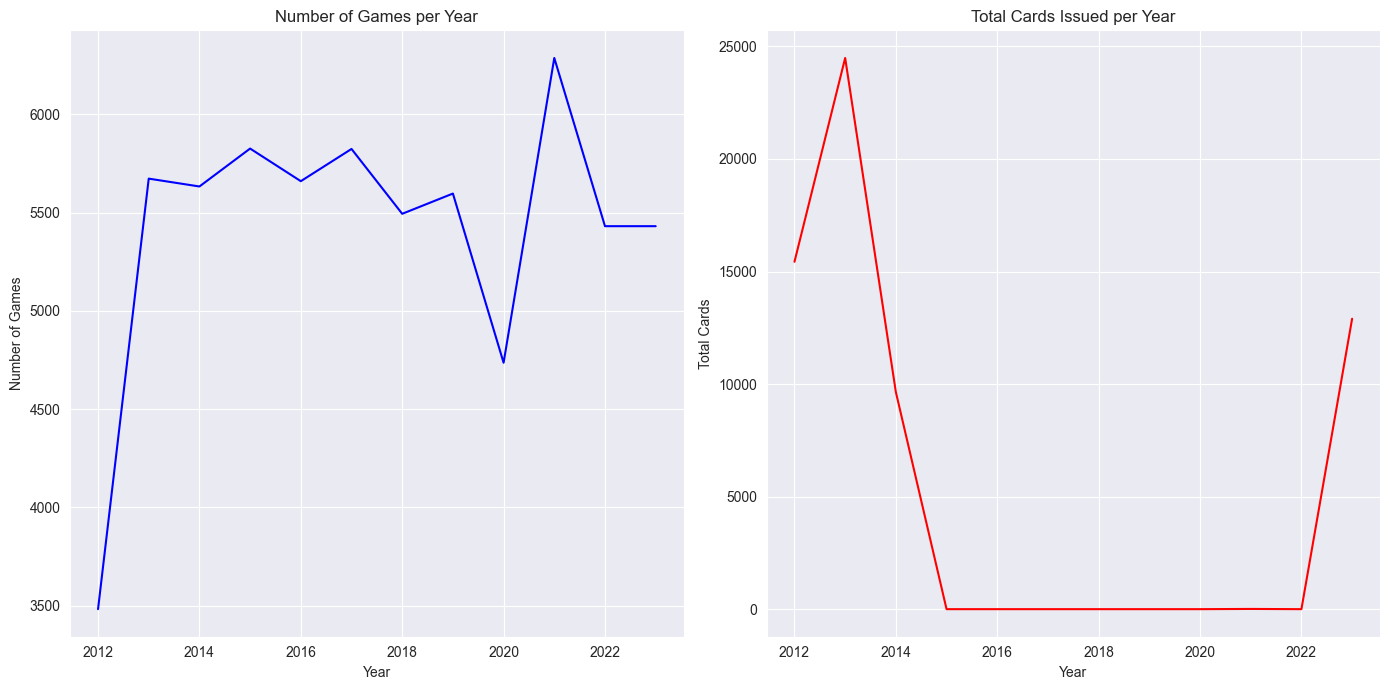

In [59]:
# Extract the year from the date column
df['year'] = df['date'].dt.year

# Group by year and aggregate the number of games and total cards
cards_per_year = df.groupby('year').agg(
    number_of_games=('game_id', 'nunique'),
    total_cards=('type', lambda x: x.str.contains('Card').sum()),
)

# Plotting the number of games and total cards in 1 row and 2 columns
plt.figure(figsize=(14, 7))

# Plot number of games
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
cards_per_year['number_of_games'].plot(kind='line', color='blue')
plt.title('Number of Games per Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.grid(True)

# Plot total cards
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
cards_per_year['total_cards'].plot(kind='line', color='red', label='Total Cards')
plt.title('Total Cards Issued per Year')
plt.xlabel('Year')
plt.ylabel('Total Cards')
plt.grid(True)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


### Number of Games and Total Cards Issued per Year

The plots show the number of games and the total cards issued per year. 
The number of games has been increasing since 2012. We have a significant decrease of the number of games in 2020, this could be due to the COVID-19 pandemic that affected the sports industry worldwide. After that we have a significant increase in the number of games in 2021 followed by a decrease in 2022 after that or values are constant till 2023 were seems to be the last year known in the dataset.

The total cards issued saw a significant increase in 2013, followed by a gradual decline until 2015. After 2015, the number of cards issued remained steady until 2022, when it increased considerably. This indicates a significant increase in the number of games in 2022 and a much higher aggression level in the games.

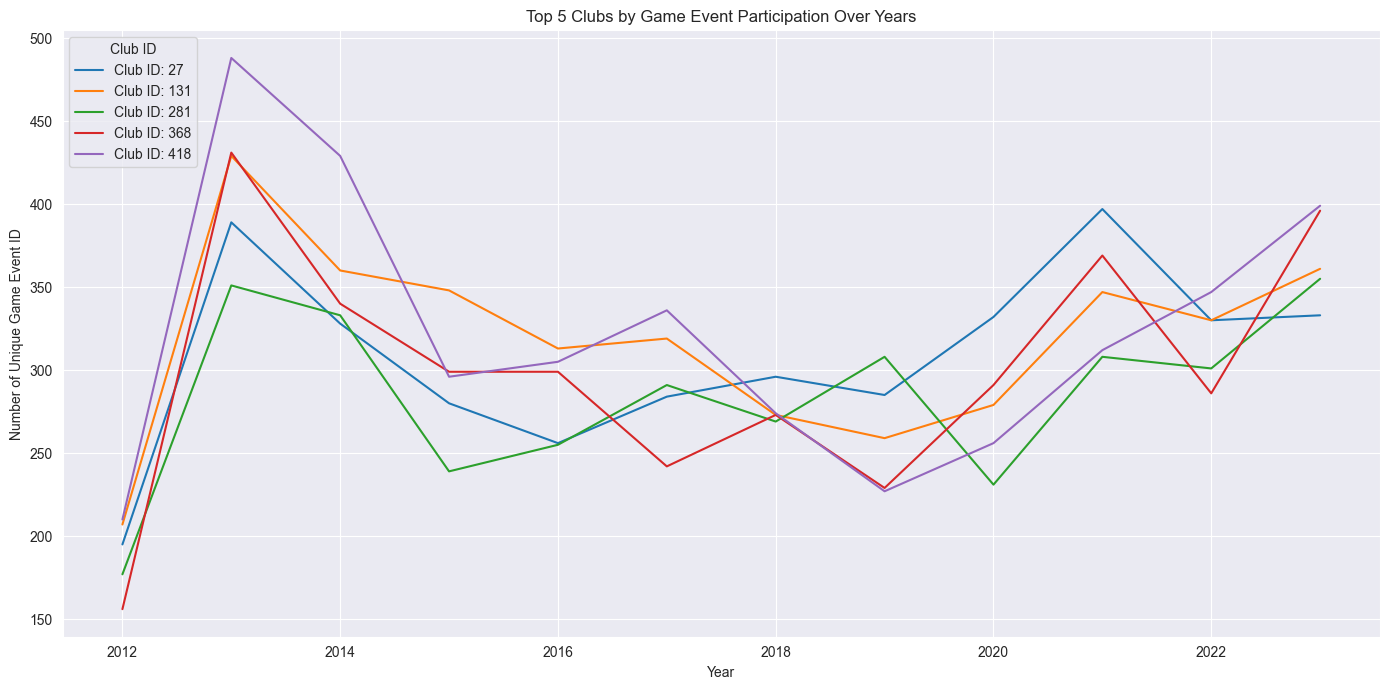

In [60]:
# Extract the year from the date column
df['year'] = df['date'].dt.year

# Count unique game_event_id for each club
club_event_participation = df.groupby('club_id')['game_event_id'].nunique()

# Get the top 5 clubs by participation
top_5_clubs = club_event_participation.nlargest(5).index

# Filter the DataFrame to include only the top 5 clubs
top_clubs_data = df[df['club_id'].isin(top_5_clubs)]

# Group by year and club_id, counting unique game_event_id for each club per year
top_clubs_yearly_events = top_clubs_data.groupby(['year', 'club_id'])['game_event_id'].nunique().unstack(fill_value=0)

# Plotting
plt.figure(figsize=(14, 7))

# Plot each club's event participation over the years
for club in top_clubs_yearly_events.columns:
    plt.plot(top_clubs_yearly_events.index, top_clubs_yearly_events[club], label=f'Club ID: {club}')

plt.title('Top 5 Clubs by Game Event Participation Over Years')
plt.xlabel('Year')
plt.ylabel('Number of Unique Game Event ID')
plt.legend(title='Club ID', loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

df.drop(columns=['year'], inplace=True)


### Top 5 Clubs by Game Event Participation Over Years

The chart shows the games event participation of the top 5 clubs over the years. The clubs are identified by their unique club ID. The participation of each club is represented by the number of unique game event IDs recorded for that club in a given year. The chart provides insights into the clubs' engagement in games over the years, highlighting any trends or changes in participation levels.

In [61]:
# Save the cleaned data to a new CSV file   
df.to_csv('../cleaned_csv/game_events_cleaned.csv', index=False)